# Freight Rate Prediction — EDA, Data Cleaning, Validation and Model Selection

**Problem:** predict the posted rate (`posted_rate`) of US truckload shipments.
**Task structure:** learn from January–October 2025 → predict November–December 2025 (`validation.csv`) and a fixed December scenario (`december_chart_inputs.csv`).

**Notebook flow**
1. Setup and data overview
2. EDA and data quality — each section: *check → finding → decision*
3. Data-cleaning decision table
4. Cleaning functions (production version: `freight/features.py`)
5. Time-based validation protocol and baselines (production version: `freight/validation.py`)
6. Final model: error analysis, final training, deliverables, experiments, `quote_signal` leak analysis, and Flatbed diagnosis
7. Reproduction

**Key findings**
- `quote_signal` looks close to the target, and its correlation with raw rate per mile is near zero — but tested inside the model it turns out to be a **month-dependent target leak**: in Jan, Feb, Mar, Jun and Sep ~15% of its rows equal the target exactly. The validation months look like the non-leaking regime and the December file lacks the column → **dropped** (section 6.6).
- `market_index` is a daily market index (~98% of its variance is between days) → **replaced by its daily mean (`mi_daily`)**. This one decision fills the missing values and supplies the December file, which has no such column.
- `log(mi)` + a ~8%/year trend explain ~84% of the day-to-day variance in normalized rate per mile → training has no December, so the trend is modeled explicitly.
- **12% of validation rows involve a city never seen in training** → location comes from coordinates, not city IDs; a cold-start test is added.
- Negative `weight` = sign error; missing values are random. Coordinates are anonymized but consistent; `distance` is sound.
- 677 rows (1.4%) with impossible rates (symmetric) → **removed from training only**; the threshold sits in a natural gap of the robust z distribution.

## 1. Setup and data overview

In [ ]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)

# Colab: /content; local default: data/ (override with DATA_DIR)
DATA = Path(os.environ.get('DATA_DIR', '/content' if Path('/content').exists() else 'data'))


def find_file(*names):
    # The assessment uses underscores (train_test.csv); some downloads use hyphens (train-test.csv)
    for n in names:
        if (DATA / n).exists():
            return DATA / n
    raise FileNotFoundError(f'none of {names} in {DATA}')


tr = pd.read_csv(find_file('train_test.csv', 'train-test.csv'), parse_dates=['date'])
va = pd.read_csv(find_file('validation.csv'), parse_dates=['date'])
dec_in = pd.read_csv(find_file('december_chart_inputs.csv', 'december-chart-inputs.csv'), parse_dates=['date'])

RAW_TRAIN_COLS = tr.columns.tolist()   # raw schema before derived columns are added
DIST_BINS = [0, 250, 500, 1000, 2000, 4000]


def hav(lat1, lon1, lat2, lon2):
    # Great-circle distance in miles
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))


def mape(y, p):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    return float((np.abs(p - y) / y).mean())

In [ ]:
for name, df in [('train', tr), ('validation', va), ('december', dec_in)]:
    na = df.isna().sum()
    print(f'{name:11s} shape={df.shape}  dates: {df.date.min().date()} → {df.date.max().date()}  missing: {na[na > 0].to_dict()}')
display(tr.head(3))

train       shape=(48000, 14)  dates: 2025-01-01 → 2025-10-31  missing: {'weight': 300, 'market_index': 374}
validation  shape=(12000, 13)  dates: 2025-11-01 → 2025-12-31  missing: {'weight': 165, 'market_index': 249}
december    shape=(31, 7)  dates: 2025-12-01 → 2025-12-31  missing: {'predicted_rate': 31}


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54


In [ ]:
# Numeric sanity check — coordinates excluded (US longitudes are always negative; not an error)
rows = []
for col in ['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate']:
    s = tr[col]
    rows.append({'column': col, 'min': s.min(), 'median': s.median(), 'max': s.max(),
                 'missing': s.isna().sum(), '<=0': (s <= 0).sum()})
display(pd.DataFrame(rows).set_index('column').round(3))

print('Duplicate load_id → train:', tr.load_id.duplicated().sum(), '| validation:', va.load_id.duplicated().sum())
print('Equipment (train):', tr.equipment.value_counts().to_dict())
print('Equipment (validation):', va.equipment.value_counts().to_dict())

,min,median,max,missing,<=0
column,,,,,
distance,70.000,953.300,3439.800,0,0
weight,-47500.000,31436.500,47500.000,300,292
market_index,0.676,1.056,1.468,374,0
quote_signal,0.692,2.056,3.610,0,0
posted_rate,57.220,2030.760,25533.000,0,0


Duplicate load_id → train: 0 | validation: 0
Equipment (train): {'Dry Van': 27202, 'Reefer': 12045, 'Flatbed': 8753}
Equipment (validation): {'Dry Van': 6780, 'Reefer': 3051, 'Flatbed': 2169}


In [ ]:
# Derived columns used throughout the analysis
tr['rpm'] = tr.posted_rate / tr.distance                  # rate per mile
tr['dist_bin'] = pd.cut(tr.distance, DIST_BINS)
# rpm normalized by the equipment × distance-band median → removes the distance/equipment effect
tr['rpm_rel'] = tr.rpm / tr.groupby(['equipment', 'dist_bin'], observed=True).rpm.transform('median')

## 2. EDA and data quality

### 2.1 `quote_signal` — leak or information?
First observation: `distance × quote_signal` is very close to `posted_rate`. This could be (a) a leak derived from the target, (b) a genuine price signal, or (c) a misleading similarity. The column is also **missing from the December file**.

In [ ]:
tr['ratio'] = tr.posted_rate / (tr.distance * tr.quote_signal)
print(tr.ratio.describe(percentiles=[.01, .05, .5, .95, .99]).round(3))
print('log-corr(rpm, quote_signal):', round(np.corrcoef(np.log(tr.rpm), np.log(tr.quote_signal))[0, 1], 4))
print('MAPE — constant rpm × distance    :', round(mape(tr.posted_rate, tr.distance * tr.rpm.median()), 4))
print('MAPE — quote_signal × distance    :', round(mape(tr.posted_rate, tr.distance * tr.quote_signal * tr.ratio.median()), 4))

count    48000.000
mean         1.100
std          0.373
min          0.147
1%           0.732
5%           0.847
50%          1.004
95%          1.613
99%          2.546
max         11.372
Name: ratio, dtype: float64
log-corr(rpm, quote_signal): 0.0101
MAPE — constant rpm × distance    : 0.1164
MAPE — quote_signal × distance    : 0.1139


In [ ]:
# Non-linear relationship? Median rpm by quote_signal decile
display(tr.groupby(pd.qcut(tr.quote_signal, 10), observed=True).rpm.median().round(2).to_frame('rpm_median').T)

# Is distance behind the U shape? quote_signal spread and within-band correlation by distance band
qs_by_bin = tr.groupby('dist_bin', observed=True).quote_signal.agg(['mean', 'std'])
qs_by_bin['within_band_corr'] = tr.groupby('dist_bin', observed=True)[['rpm', 'quote_signal']].apply(
    lambda g: np.corrcoef(np.log(g.rpm), g.quote_signal)[0, 1])
display(qs_by_bin.round(3))

quote_signal,"(0.691, 1.735]","(1.735, 1.851]","(1.851, 1.928]","(1.928, 1.994]","(1.994, 2.056]","(2.056, 2.118]","(2.118, 2.185]","(2.185, 2.266]","(2.266, 2.403]","(2.403, 3.61]"
rpm_median,2.53,2.28,2.03,2.01,2.07,2.08,2.11,2.18,2.29,2.55


,mean,std,within_band_corr
dist_bin,,,
"(0, 250]",2.116,0.693,0.024
"(250, 500]",2.081,0.407,0.006
"(500, 1000]",2.066,0.227,0.053
"(1000, 2000]",2.051,0.164,0.075
"(2000, 4000]",2.040,0.205,0.116


**Finding**
- Median ratio ≈ 1.00 but log-correlation ≈ **0.01**; naive MAPE 11.4% (a plain copy of the target would give ~1–3%).
- Using `quote_signal` gains only **0.25 points** over a constant rpm (11.64 → 11.39).
- The decile table is **U-shaped** because of distance: quote_signal is very noisy on short hauls (SD 0.69 → 0.16 on long hauls), and short hauls produce both extreme quote_signal and high rpm.
- Within distance bands the correlation is ≈ 0; **0.006 in the (250, 500] band** of the December lane.

**Decision:** `quote_signal` is **dropped**. ⚠️ *The "carries no information" reading above is corrected in section 6.6:* the relationship with raw price is indeed a distance artifact, but tested inside the model `quote_signal` turns out to contain exact copies of the target in some months (a month-dependent leak). The real justification is in 6.6.

### 2.2 `market_index` — at what granularity does it vary?

In [ ]:
mi_ok = tr.dropna(subset=['market_index'])
per_day = mi_ok.groupby('date').market_index.agg(['mean', 'std', 'nunique', 'size'])
print('Distinct values per day (median):', per_day['nunique'].median(), '| rows per day (median):', per_day['size'].median())
print('SD of daily means:', round(per_day['mean'].std(), 4), '| mean within-day SD:', round(per_day['std'].mean(), 4))
print('corr(log rpm, market_index):', round(np.corrcoef(np.log(mi_ok.rpm), mi_ok.market_index)[0, 1], 4))

display(pd.DataFrame({'rpm_rel': tr.groupby(tr.date.dt.month).rpm_rel.median(),
                      'market_index': tr.groupby(tr.date.dt.month).market_index.mean()}).round(3).T)

Distinct values per day (median): 154.5 | rows per day (median): 156.0
SD of daily means: 0.1665 | mean within-day SD: 0.0249
corr(log rpm, market_index): 0.113


date,1,2,3,4,5,6,7,8,9,10
rpm_rel,0.946,0.962,0.995,1.001,1.024,1.049,1.020,0.988,1.004,1.007
market_index,0.927,0.996,1.073,1.208,1.301,1.280,1.201,0.981,0.893,0.958


In [ ]:
# Is every December day represented in validation.csv (as an input)?
dec_mi = va[va.date.dt.month == 12].groupby('date').market_index.agg(['mean', 'count'])
print(len(dec_mi), 'days | min rows per day:', dec_mi['count'].min())
print(dec_mi['mean'].describe().round(3))

31 days | min rows per day: 159
count    31.000
mean      0.934
std       0.071
min       0.831
25%       0.865
50%       0.924
75%       0.998
max       1.045
Name: mean, dtype: float64


**Finding**
- Almost every load has its own value (~150 distinct values per day), but **SD of daily means 0.167 ≫ within-day SD 0.025** → **~98% of the variance is between days** (0.167² / (0.167² + 0.025²)); the load-level part is small noise.
- Clear seasonality: May–June peak (~1.30), September trough (~0.89).
- All 31 December days are in validation.csv with ≥159 rows each; December mean ≈ 0.93.

**Decision:** replace `market_index` with **`mi_daily`** (mean over all loads of the same date; input column only, never the target).
- Fills the missing values (374 in train, 249 in validation).
- Gives the December scenario a value from the same-date rows of `validation.csv`.
- Train, validation and December see the same feature definition (train/serve consistency).
- Assumption (stated in the report): *the day's market index is known at quote time.*

### 2.3 Date signal — what will shape the December chart?
In the December scenario **only the date changes**, so the chart's shape is entirely driven by date-derived features.

In [ ]:
daily = tr.groupby('date').agg(rpm_rel=('rpm_rel', 'median'), mi=('market_index', 'mean'))
y_daily = np.log(daily.rpm_rel)
T0 = daily.index[0]
feats_daily = {'log_mi': np.log(daily.mi), 't_month': (daily.index - T0).days / 30}


def fit_daily(cols):
    # log(daily rpm_rel) ~ const + selected features (OLS)
    X = np.column_stack([np.ones(len(y_daily))] + [np.asarray(feats_daily[c]) for c in cols])
    b, *_ = np.linalg.lstsq(X, y_daily.to_numpy(), rcond=None)
    resid = y_daily.to_numpy() - X @ b
    r2 = 1 - (resid ** 2).sum() / ((y_daily - y_daily.mean()) ** 2).sum()
    return pd.Series({'R2': r2, **dict(zip(['const'] + cols, b))})


display(pd.DataFrame({' + '.join(c): fit_daily(c) for c in [['log_mi'], ['t_month'], ['log_mi', 't_month']]}).T.round(4))

dow = tr.groupby(tr.date.dt.dayofweek).rpm_rel.median().round(3)
dow.index = dow.index.map(dict(enumerate(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])))
display(dow.to_frame('rpm_rel_median').T)

,R2,const,log_mi,t_month
log_mi,0.4816,-0.0104,0.1416,NaN
t_month,0.2609,-0.0286,NaN,0.0055
log_mi + t_month,0.8383,-0.0440,0.1561,0.0064


date,Mon,Tue,Wed,Thu,Fri,Sat,Sun
rpm_rel_median,0.991,0.998,1.008,1.011,1.006,0.996,0.989


**Finding**

| Model | R² |
|---|---|
| `log_mi` only | 0.48 |
| trend only | 0.26 |
| **`log_mi` + trend** | **0.84** |

- The two mask each other (e.g. September: market index at its low, while the trend pushes prices up).
- **Elasticity ≈ 0.156** (mi +10% → price ~+1.5%); **trend ≈ 0.64%/month** (~8%/year).
- Day of week: Wed–Thu peak, Sunday low; peak-to-trough ~2.2%.

**Implication:** tree models (GBM) cannot carry the trend beyond October (they stay flat). Options — plain GBM / detrend + GBM / two-stage (linear market-time + GBM residual) — are compared **on validation**.

### 2.4 Coordinates and distance
In `head()` the coordinates do not match the real cities (e.g. Baltimore's longitude lies in the Atlantic, Los Angeles' latitude in Mexico).

In [ ]:
cols = ['city', 'lat', 'lon']
cities = pd.concat([tr[['pickup', 'pickup_lat', 'pickup_lon']].set_axis(cols, axis=1),
                    tr[['delivery', 'delivery_lat', 'delivery_lon']].set_axis(cols, axis=1)])
print(cities.city.nunique(), 'cities | max distinct coordinates per city:',
      cities.groupby('city')[['lat', 'lon']].nunique().max().max())
print('pickup == delivery:', (tr.pickup == tr.delivery).sum())

known = set(cities.city)
print('Cities in validation but not in train:', (set(va.pickup) | set(va.delivery)) - known or 'none')
print('Cities in December file but not in train:', (set(dec_in.pickup) | set(dec_in.delivery)) - known or 'none')

64 cities | max distinct coordinates per city: 1
pickup == delivery: 0
Cities in validation but not in train: {'Laredo', 'San Diego', 'Allentown', 'Charlotte', 'Norfolk', 'Knoxville', 'Chicago', 'Jackson'}
Cities in December file but not in train: none


In [ ]:
# Validation cities/lanes never seen in training: how many rows are affected?
new_cities = (set(va.pickup) | set(va.delivery)) - known
p_new, d_new = va.pickup.isin(new_cities), va.delivery.isin(new_cities)
va_new = p_new | d_new
print('New cities:', sorted(new_cities))
print('Affected validation rows:', va_new.sum(), f'({va_new.mean():.1%})',
      '| pickup only:', (p_new & ~d_new).sum(), '| delivery only:', (~p_new & d_new).sum(),
      '| both:', (p_new & d_new).sum())
display(va.loc[va_new, 'date'].dt.month.value_counts().sort_index().to_frame('affected_rows').T)

# A lane (pickup → delivery) can be unseen even when both cities are known
lane_seen = pd.MultiIndex.from_frame(va[['pickup', 'delivery']]).isin(pd.MultiIndex.from_frame(tr[['pickup', 'delivery']]))
print('Lanes never seen in training:', (~lane_seen).sum(), f'({(~lane_seen).mean():.1%})',
      '| of which both cities known:', (~lane_seen & ~va_new.to_numpy()).sum())

# Do cities enter the training data over time? (does internal validation ever see a cold start?)
first_seen = cities.assign(date=np.concatenate([tr.date.to_numpy(), tr.date.to_numpy()])).groupby('city').date.min()
display(first_seen.dt.month.value_counts().sort_index().to_frame('cities_first_seen').T)

New cities: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Affected validation rows: 1447 (12.1%) | pickup only: 725 | delivery only: 722 | both: 0


date,11,12
affected_rows,721,726


Lanes never seen in training: 1461 (12.2%) | of which both cities known: 14


date,1
cities_first_seen,64


In [ ]:
tr['circuity'] = tr.distance / hav(tr.pickup_lat, tr.pickup_lon, tr.delivery_lat, tr.delivery_lon)
lane_med = tr.groupby(['pickup', 'delivery']).distance.transform('median')
tr['dist_dev'] = tr.distance / lane_med
display(tr[['circuity', 'dist_dev']].describe(percentiles=[.01, .05, .5, .95, .99]).round(3))
print('Max distinct distances per lane:', tr.groupby(['pickup', 'delivery']).distance.nunique().max())

,circuity,dist_dev
count,48000.000,48000.000
mean,1.195,1.000
std,0.144,0.022
min,1.058,0.759
1%,1.130,0.943
5%,1.143,0.967
50%,1.182,1.000
95%,1.273,1.034
99%,1.404,1.058
max,9.635,1.283


Max distinct distances per lane: 38


In [ ]:
# Are circuity extremes distance errors? Which distance is the price consistent with?
sus = tr.circuity > 1.5
print('Suspicious rows (circuity > 1.5):', sus.sum(), '| median distance:', tr.loc[sus, 'distance'].median())
print('median rpm — normal rows                  :', round(tr.loc[~sus, 'rpm'].median(), 2))
print('median rpm — suspicious, stated distance  :', round(tr.loc[sus, 'rpm'].median(), 2))
print('median rpm — suspicious, lane-median dist.:', round((tr.posted_rate / lane_med)[sus].median(), 2))

Suspicious rows (circuity > 1.5): 214 | median distance: 88.55
median rpm — normal rows                  : 2.14
median rpm — suspicious, stated distance  : 2.91
median rpm — suspicious, lane-median dist.: 3.13


**Finding**
- 64 cities, each with **one** coordinate → coordinates are shifted (anonymized) but consistent.
- **8 cities in validation never appear in training** (Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego); the December cities are known. **1,447 rows (12.1%)** are affected, always with exactly one new endpoint (725 pickup, 722 delivery, 0 both). Only 14 other rows fall on an unseen lane between known cities. **Every city already appears in January** → the time-based folds never test a cold start. City IDs / lane target encoding cannot work for these rows → the model must learn location from **coordinates**.
- `distance` varies only ±3% within a lane (`dist_dev` 1%–99%: 0.94–1.06) → natural variation, not errors.
- `circuity` extremes (214 rows): an inflated distance would give a *low* rpm, but it is *high* (2.91 vs 2.14); these rows have a median distance of only ~89 miles (short haul → high rpm) → distance is correct; the extremes come from the coordinate shift artificially bringing some cities closer.

**Decision:** `distance` is left as is. Coordinates are used only as **location features**; no great-circle distance / circuity is derived and no real-world coordinates are added. December coordinates come from the **training map**. For new cities: no ID-based features, plus a separate **cold-start metric**.

### 2.5 `weight` — negatives and missing values

In [ ]:
w = tr.weight
q = [.05, .25, .5, .75, .95]
display(pd.DataFrame({'positive': w[w > 0].quantile(q), '|negative|': (-w[w < 0]).quantile(q)}).round().T)
print('Train → zero:', (w == 0).sum(), '| negative:', (w < 0).sum(), '| missing:', w.isna().sum())
print('Validation → zero:', (va.weight == 0).sum(), '| negative:', (va.weight < 0).sum(), '| missing:', va.weight.isna().sum())

tr['w_bad'] = w.isna() | (w <= 0)
display(tr.groupby('w_bad').rpm_rel.median().round(3).to_frame('rpm_rel_median').T)

tr['w_fix'] = w.abs().replace(0, np.nan)
display(tr.groupby(pd.qcut(tr.w_fix, 5), observed=True).rpm_rel.median().round(3).to_frame('rpm_rel_median').T)

,0.05,0.25,0.50,0.75,0.95
positive,18004.0,25922.0,31494.0,37063.0,44962.0
|negative|,18966.0,25928.0,31822.0,37284.0,46070.0


Train → zero: 0 | negative: 292 | missing: 300
Validation → zero: 0 | negative: 145 | missing: 165


w_bad,False,True
rpm_rel_median,1.0,1.001


w_fix,"(4999.999, 24589.8]","(24589.8, 29380.0]","(29380.0, 33600.4]","(33600.4, 38411.4]","(38411.4, 47500.0]"
rpm_rel_median,0.964,0.983,1.002,1.02,1.03


**Finding**
- `|negative|` quantiles match the positive ones (median 31,822 vs 31,494) → **sign error**. No zeros.
- Rows with bad weight are priced like the rest (rpm_rel 1.001 vs 1.000) → missingness is **random**; no flag needed.
- Weight has a moderate, monotone effect: lightest → heaviest quintile rpm +~7%. The December scenario's 32,000 lb is in the middle quintile (neutral).

**Decision:** `abs()`; missing values are **not imputed** — left to LightGBM's native missing-value handling (no imputation means nothing is fitted outside the training folds).

### 2.6 `posted_rate` outliers
Robust z-score (MAD) of **rate per mile** (not raw rate) within equipment × distance band.

In [ ]:
lr = np.log(tr.rpm)
grp = [tr.equipment, tr.dist_bin]
med = lr.groupby(grp, observed=True).transform('median')
mad = (lr - med).abs().groupby(grp, observed=True).transform('median')
tr['rz'] = (lr - med) / (1.4826 * mad)
tr['mult'] = np.exp(lr - med)                 # multiple of the group median
out = tr.rz.abs() > 4

print('Outliers:', out.sum(), '| above:', (tr.rz > 4).sum(), '| below:', (tr.rz < -4).sum())
display(pd.cut(tr.rz.abs(), [-0.01, 2, 3, 4, 5, 6, np.inf]).value_counts().sort_index().to_frame('rows').T)
display(pd.cut(tr.mult[out], [0, 0.2, 0.5, 2, 5, 15, 100]).value_counts().sort_index().to_frame('rows').T)

Outliers: 677 | above: 340 | below: 337


rz,"(-0.01, 2.0]","(2.0, 3.0]","(3.0, 4.0]","(4.0, 5.0]","(5.0, 6.0]","(6.0, inf]"
rows,45612,1665,46,0,0,677


mult,"(0.0, 0.2]","(0.2, 0.5]","(0.5, 2.0]","(2.0, 5.0]","(5.0, 15.0]","(15.0, 100.0]"
rows,44,293,0,322,18,0


In [ ]:
display(pd.crosstab(out, sus, rownames=['rpm outlier'], colnames=['distance suspicious']))
display(tr.loc[out, 'date'].dt.month.value_counts().sort_index().to_frame('outliers').T)   # clustered in time?
display(tr.loc[out, ['pickup', 'delivery', 'distance', 'equipment', 'date', 'posted_rate', 'rpm', 'mult']].head(8).round({'rpm': 2, 'mult': 2}))

distance suspicious,False,True
rpm outlier,,
False,47117,206
True,669,8


date,1,2,3,4,5,6,7,8,9,10
outliers,81,57,71,66,62,63,65,68,64,80


,pickup,delivery,distance,equipment,date,posted_rate,rpm,mult
50,Los Angeles,Green Bay,2202.5,Reefer,2025-01-01,1243.45,0.56,0.27
190,Tampa,Milwaukee,919.8,Dry Van,2025-01-02,704.89,0.77,0.36
294,Greensboro,Syracuse,685.6,Dry Van,2025-01-02,518.31,0.76,0.36
388,Corpus Christi,Chattanooga,823.0,Flatbed,2025-01-03,5485.49,6.67,2.92
439,Richmond,Charleston,394.9,Dry Van,2025-01-03,276.27,0.70,0.30
469,Phoenix,Jacksonville,2154.3,Dry Van,2025-01-04,10854.69,5.04,2.74
508,Las Vegas,Grand Rapids,1976.4,Flatbed,2025-01-04,699.41,0.35,0.17
785,Kansas City,Charleston,861.5,Dry Van,2025-01-06,4587.83,5.33,2.53


**Finding**
- **677 rows (1.4%)**, symmetric: 340 above / 337 below; spread evenly across months (57–81/month) → not a market shock.
- Multiples in 0.2–0.5 and 2–5; no cluster at 10× / 100× (not a unit error) → random multiplicative corruption.
- Economically impossible examples (e.g. LA → Green Bay, 2,200 miles Reefer, $0.56/mile).
- Only **8** overlap with distance-suspicious rows → two separate problems.
- **Threshold sensitivity:** the |z| ∈ (4, 6] range is **empty**; the clean tail ends near 4 and all corrupted rows are above 6. Thresholds of 4, 5 or 6 select exactly the same rows.

**Decision:** these rows are removed **from training only**. Validation labels may carry the same noise; we cannot fix it → predict the median clean price and report internal test metrics on both **raw** and **clean** labels.

### 2.7 Reference for the December scenario: Lexington → Fort Wayne

In [ ]:
city_xy = cities.drop_duplicates('city').set_index('city')[['lat', 'lon']]
lx, fw = city_xy.loc['Lexington'], city_xy.loc['Fort Wayne']
print('Distance from coordinates:', round(hav(lx.lat, lx.lon, fw.lat, fw.lon) * tr.circuity.median(), 1), '(file says 360)')

lf = tr[(tr.pickup == 'Lexington') & (tr.delivery == 'Fort Wayne') & ~out]
display(lf.groupby('equipment').agg(n=('rpm', 'size'), distance=('distance', 'median'),
                                    rate=('posted_rate', 'median'), rpm=('rpm', 'median')).round(2))

Distance from coordinates: 354.0 (file says 360)


,n,distance,rate,rpm
equipment,,,,
Dry Van,21,362.5,807.89,2.23
Flatbed,3,357.8,877.84,2.47
Reefer,8,365.8,934.50,2.57


In [ ]:
# Rough December expectation: move the Dry Van median to December with the mi_daily and trend differences (sanity check only)
b = fit_daily(['log_mi', 't_month'])
dv = lf[lf.equipment == 'Dry Van']
log_mi_ref = np.log(dv.date.map(daily.mi)).mean()
t_ref = ((dv.date - T0).dt.days / 30).mean()

dec_curve = pd.DataFrame({'mi': dec_mi['mean']})
dec_curve['t_month'] = (dec_curve.index - T0).days / 30
dec_curve['expected'] = dv.posted_rate.median() * np.exp(
    b['log_mi'] * (np.log(dec_curve.mi) - log_mi_ref) + b['t_month'] * (dec_curve.t_month - t_ref))
print('Dry Van median rate (Jan–Oct):', round(dv.posted_rate.median(), 2))
print(dec_curve.expected.describe().round(1))

Dry Van median rate (Jan–Oct): 807.89
count     31.0
mean     832.8
std       10.3
min      815.9
25%      824.5
50%      832.3
75%      841.7
max      849.4
Name: expected, dtype: float64


**Finding:** the lane is consistent with the data (~354 miles from coordinates vs 360). Training has 21 Dry Van loads on this lane, median rate ~$808. Adjusting with `log_mi` + trend gives a rough December band of **$816–849 (mean ~$833)**.

**Use:** not a target but a **sanity check**. Predictions far outside this band (e.g. a flat line, $600 or $1,100) would signal a bug.

## 3. Data-cleaning decision table

| Issue | Evidence | Decision | Applied to |
|---|---|---|---|
| `quote_signal` | In 5 months ~15% of rows are exact copies of the target (leak), 4–12% biased in the others; validation looks like the non-leaking regime; absent in December (see 6.6) | **Drop** | All |
| `market_index` missing + absent in December | ~98% of variance is between days; within-day SD 0.025 | **`mi_daily`** (daily mean) | All |
| Negative `weight` | Absolute values match the positive distribution | **`abs()`** | All |
| Missing `weight` | No price difference → random | Not imputed; LightGBM handles it | All |
| Coordinates don't match real cities | Shifted, but one coordinate per city | Use as location; no derived distances | All |
| `circuity` extremes (214) | Price consistent with stated distance; 8 overlaps with rate outliers | **Keep** | — |
| 8 unseen cities in validation | Never appear in training; coordinates are present in validation | Learn location from coordinates; no ID features; separate cold-start metric | Model design |
| Rate outliers (677) | Symmetric, impossible rpm, multiples 0.2–0.5 / 2–5; z ∈ (4, 6] empty | **Remove** | **Training only** |

**Principle:** feature transformations are identical for every dataset; **rows are removed from training only** (all 12,000 validation rows need a prediction).

## 4. Cleaning functions (production version: `freight/features.py`)

In [ ]:
CITY_XY = city_xy.copy()   # training map: city → (lat, lon)


def build_mi_daily(*frames):
    # Daily market index: from the input column (market_index) only, never the target
    df = pd.concat([f[['date', 'market_index']] for f in frames], ignore_index=True)
    df['date'] = pd.to_datetime(df['date'])
    return df.groupby('date')['market_index'].mean()


def add_coords(df, city_xy=CITY_XY):
    # Adds lat/lon from the training map for inputs that lack them (the December file)
    res = df.copy()
    for side in ['pickup', 'delivery']:
        res[f'{side}_lat'] = res[side].map(city_xy['lat'])
        res[f'{side}_lon'] = res[side].map(city_xy['lon'])
    return res


def clean_features(df, mi_daily):
    # Same feature cleaning for every dataset (train / validation / December)
    res = df.copy()
    res['date'] = pd.to_datetime(res['date'])
    res['weight'] = res['weight'].abs().replace(0, np.nan)   # sign error; 0 → missing
    res['mi_daily'] = res['date'].map(mi_daily)              # daily market index
    return res.drop(columns=['quote_signal', 'market_index'], errors='ignore')


def outlier_mask(df, z=4.0):
    # Robust z-score of log(rpm) within equipment × distance band. ONLY for dropping training rows.
    lr = np.log(df['posted_rate'] / df['distance'])
    g = [df['equipment'], pd.cut(df['distance'], DIST_BINS)]
    med = lr.groupby(g, observed=True).transform('median')
    mad = (lr - med).abs().groupby(g, observed=True).transform('median')
    return ((lr - med) / (1.4826 * mad)).abs() > z

In [ ]:
mi_daily = build_mi_daily(tr, va)

train_c = clean_features(tr[RAW_TRAIN_COLS], mi_daily)
valid_c = clean_features(va, mi_daily)
dec_c = clean_features(add_coords(dec_in), mi_daily)

# Sanity checks
assert outlier_mask(train_c).sum() == out.sum(), 'outlier_mask must select the same rows as the EDA'
assert (train_c.weight.dropna() > 0).all() and (valid_c.weight.dropna() > 0).all()
for name, df in [('train', train_c), ('validation', valid_c), ('december', dec_c)]:
    assert df.mi_daily.notna().all(), f'{name}: mi_daily missing'
assert dec_c[['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']].notna().all().all()
assert len(valid_c) == 12_000 and valid_c.load_id.is_unique

print('train :', train_c.shape, '| outliers to remove:', outlier_mask(train_c).sum())
print('valid :', valid_c.shape, '| missing weight (not imputed, LightGBM handles it):', valid_c.weight.isna().sum())
print('dec   :', dec_c.shape)
display(dec_c.head(3))

train : (48000, 13) | outliers to remove: 677
valid : (12000, 12) | missing weight (not imputed, LightGBM handles it): 165
dec   : (31, 12)


,pickup,delivery,distance,equipment,weight,date,predicted_rate,pickup_lat,pickup_lon,delivery_lat,delivery_lon,mi_daily
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN,36.99152,-84.99876,41.31561,-85.36206,0.834919
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN,36.99152,-84.99876,41.31561,-85.36206,0.914680
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN,36.99152,-84.99876,41.31561,-85.36206,0.994063


## 5. Time-based validation protocol (production version: `freight/validation.py`)

**Why not random K-fold?** The same day, the same lane and the same `mi_daily` would sit in both training and test, and the trend would be seen from both sides → optimistic scores that do not measure the real task.

**Design:** expanding window, two-month horizon (real task: learn until October → predict two months ahead).

| Fold | Train | Test |
|---|---|---|
| F1 | Jan–Apr | May–Jun |
| F2 | Jan–Jun | Jul–Aug |
| F3 | Jan–Aug | **Sep–Oct** (closest to the real task; market regime similar to December) |

**Rules**
1. Outlier removal is computed and applied on each fold's **training part**; test rows are never touched.
2. Two test views: **raw** (what the grader will see) and **clean** (corrupted labels excluded).
3. Everything derived from the target (trend slope, any encodings) is learned **from the training part only**.
4. Metric: the grader's metric is unknown → MAE, MAPE and RMSE are reported; **MAPE** drives model selection.

In [ ]:
FOLDS = [('2025-05-01', '2025-07-01'),
         ('2025-07-01', '2025-09-01'),
         ('2025-09-01', '2025-11-01')]


def temporal_folds(df):
    # Expanding window: everything before the test start is training
    for start, end in FOLDS:
        start_ts, end_ts = pd.Timestamp(start), pd.Timestamp(end)
        train_idx = df.index[df['date'] < start_ts]
        test_idx = df.index[(df['date'] >= start_ts) & (df['date'] < end_ts)]
        yield start, train_idx, test_idx


def metrics(y, p):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    err = y - p
    return {'MAE': np.abs(err).mean(), 'MAPE': (np.abs(err) / y).mean(), 'RMSE': np.sqrt((err ** 2).mean())}


def evaluate(df, fit_predict):
    # fit_predict(train_df, test_df) -> predictions. Every model goes through the same protocol.
    rows = []
    for start, tr_idx, te_idx in temporal_folds(df):
        train = df.loc[tr_idx]
        train = train[~outlier_mask(train)]                 # rule 1: training part only
        test = df.loc[te_idx]
        pred = np.asarray(fit_predict(train, test), dtype=float)
        y = test['posted_rate'].to_numpy()
        clean = (~outlier_mask(test)).to_numpy()           # rule 2: for reporting only
        for view, m in [('raw', np.ones(len(y), dtype=bool)), ('clean', clean)]:
            rows.append({'fold': start, 'view': view, **metrics(y[m], pred[m])})
    return pd.DataFrame(rows)


display(pd.DataFrame([{'test_start': s, 'train_rows': len(a), 'test_rows': len(t)}
                      for s, a, t in temporal_folds(train_c)]))

,test_start,train_rows,test_rows
0,2025-05-01,19110,9696
1,2025-07-01,28806,9671
2,2025-09-01,38477,9523


In [ ]:
# Protocol test — simplest baseline: global median rpm × distance
def baseline_global_rpm(train, test):
    return test['distance'] * (train['posted_rate'] / train['distance']).median()


res = evaluate(train_c, baseline_global_rpm)
display(res.round(4))
display(res.groupby('view')[['MAE', 'MAPE', 'RMSE']].mean().round(4))

,fold,view,MAE,MAPE,RMSE
0,2025-05-01,raw,241.7797,0.1189,671.8428
1,2025-05-01,clean,189.8316,0.0982,244.8750
2,2025-07-01,raw,249.0163,0.1116,674.7212
3,2025-07-01,clean,199.1517,0.0903,289.8759
4,2025-09-01,raw,256.9519,0.1163,684.2471
5,2025-09-01,clean,203.6855,0.0927,295.9247


,MAE,MAPE,RMSE
view,,,
clean,197.5562,0.0937,276.8919
raw,249.2493,0.1156,676.9370


### 5.1 Baselines (the bars to beat)
- **B1** global median rpm × distance
- **B2** lane × equipment median rpm × distance; if the lane has fewer than 5 training loads (new lane / new city) it **falls back to equipment × distance band**
- **B3** B2 + `log(mi_daily)` elasticity + trend (OLS on B2 residuals; coefficients from the training part only)

In [ ]:
def lane_rpm_table(train, min_n=5):
    # From the training part: lane × equipment median log(rpm) (at least min_n rows) + equipment × distance-band fallback
    d = train.assign(lrpm=np.log(train['posted_rate'] / train['distance']),
                     dist_bin=pd.cut(train['distance'], DIST_BINS).astype(str))
    lane = d.groupby(['pickup', 'delivery', 'equipment']).lrpm.agg(['median', 'size'])
    lane = lane.loc[lane['size'] >= min_n, 'median'].rename('lane')
    fb = d.groupby(['equipment', 'dist_bin']).lrpm.median().rename('fb')
    return lane, fb


def base_log_rpm(df, lane, fb):
    # Lane value if available, else (new lane / new city / few rows) the equipment × distance band
    d = df[['pickup', 'delivery', 'equipment', 'distance']].copy()
    d['dist_bin'] = pd.cut(d['distance'], DIST_BINS).astype(str)
    d = d.merge(lane, left_on=['pickup', 'delivery', 'equipment'], right_index=True, how='left')
    d = d.merge(fb, left_on=['equipment', 'dist_bin'], right_index=True, how='left')
    return d['lane'].fillna(d['fb']).to_numpy(), d['lane'].notna().to_numpy()


def baseline_lane(train, test):                       # B2
    lane, fb = lane_rpm_table(train)
    base, _ = base_log_rpm(test, lane, fb)
    return test['distance'].to_numpy() * np.exp(base)


def time_feats(df):
    t = (df['date'] - pd.Timestamp('2025-01-01')).dt.days / 30
    return np.column_stack([np.ones(len(df)), np.log(df['mi_daily']), t])


def baseline_lane_market(train, test):                # B3 = B2 + mi_daily elasticity + trend
    lane, fb = lane_rpm_table(train)
    base_tr, _ = base_log_rpm(train, lane, fb)
    resid = np.log(train['posted_rate'] / train['distance']).to_numpy() - base_tr
    b, *_ = np.linalg.lstsq(time_feats(train), resid, rcond=None)
    base_te, _ = base_log_rpm(test, lane, fb)
    return test['distance'].to_numpy() * np.exp(base_te + time_feats(test) @ b)


# Lane coverage: share of test rows that use a lane value vs the fallback
for start, tr_idx, te_idx in temporal_folds(train_c):
    trn = train_c.loc[tr_idx]
    lane, fb = lane_rpm_table(trn[~outlier_mask(trn)])
    _, has_lane = base_log_rpm(train_c.loc[te_idx], lane, fb)
    print(start, f'test rows with a lane value: {has_lane.mean():.1%}')

results = pd.concat({name: evaluate(train_c, fn).groupby('view')[['MAE', 'MAPE', 'RMSE']].mean()
                     for name, fn in [('B1 global rpm', baseline_global_rpm),
                                      ('B2 lane rpm', baseline_lane),
                                      ('B3 lane rpm + market + trend', baseline_lane_market)]})
display(results.round(4))

2025-05-01 test rows with a lane value: 17.3%
2025-07-01 test rows with a lane value: 34.2%
2025-09-01 test rows with a lane value: 47.3%


MAE    MAPE      RMSE
                             view                             
B1 global rpm                clean  197.5562  0.0937  276.8919
                             raw    249.2493  0.1156  676.9370
B2 lane rpm                  clean  103.8456  0.0449  141.9815
                             raw    157.1816  0.0678  644.9133
B3 lane rpm + market + trend clean   95.5914  0.0417  133.7942
                             raw    148.9692  0.0654  637.9209

**Finding (mean of 3 folds)**

| Model | MAPE raw | MAPE clean | RMSE raw | RMSE clean |
|---|---|---|---|---|
| B1 global rpm | 11.56% | 9.37% | 677 | 277 |
| B2 lane rpm | 6.78% | 4.49% | 645 | 142 |
| B3 lane rpm + market + trend | **6.54%** | **4.17%** | 638 | 134 |

- Lane/location information halves the error; market + trend adds a small but consistent gain (~0.3 points), in line with the ±5% date effect from the EDA.
- Lane coverage is low (only 47% of F3 test rows have a lane value; the rest use the equipment × distance-band fallback) → room for a model that generalizes location (coordinate-based GBM).
- **Label noise:** ~2.4 points of MAPE and a ~5× RMSE gap between raw and clean labels: corrupted labels dominate the raw metrics and no model can fix them → model selection uses the **clean** view.

### 5.2 GBM — design decisions
- **Target:** `log(posted_rate / distance)` = log(rpm). Pricing is multiplicative (distance × rpm × market^0.156 × trend); the log makes it additive, approximates relative-error (MAPE) optimization and keeps predictions positive.
- **Features:** pickup/delivery coordinates, log(distance), equipment, weight, log(`mi_daily`), day of week, trend. **No city IDs or lane target encoding:** 12% of validation rows involve a city absent from training, and coordinates exist for those cities too.
- **Missing weight:** LightGBM handles missing values natively, so no imputation is needed.
- **Two trend variants:** GBM-A treats the trend as an ordinary feature (flat after October); GBM-B removes a linear trend from the target and adds it back at prediction time (extrapolates).

In [ ]:
import lightgbm as lgb

T_START = pd.Timestamp('2025-01-01')
EQUIP = pd.CategoricalDtype(['Dry Van', 'Flatbed', 'Reefer'])


def make_X(df, with_trend=True):
    # No city IDs: location comes from coordinates only, so new cities generalize
    X = pd.DataFrame({
        'pickup_lat': df['pickup_lat'], 'pickup_lon': df['pickup_lon'],
        'delivery_lat': df['delivery_lat'], 'delivery_lon': df['delivery_lon'],
        'log_dist': np.log(df['distance']),
        'equipment': df['equipment'].astype(EQUIP),
        'weight': df['weight'],                      # LightGBM handles missing values
        'log_mi': np.log(df['mi_daily']),
        'dow': df['date'].dt.dayofweek,
    }, index=df.index)
    if with_trend:
        X['t_month'] = (df['date'] - T_START).dt.days / 30
    return X


GBM_PARAMS = dict(n_estimators=800, learning_rate=0.03, num_leaves=63, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=42,
                  deterministic=True, force_row_wise=True)   # fully reproducible


def log_rpm(df):
    return np.log(df['posted_rate'] / df['distance']).to_numpy()


def gbm_plain(train, test):
    # GBM-A: target log(rpm); trend is an ordinary feature (stays flat after October)
    m = lgb.LGBMRegressor(**GBM_PARAMS).fit(make_X(train), log_rpm(train))
    return test['distance'].to_numpy() * np.exp(m.predict(make_X(test)))


def trend_beta(train):
    # Trend slope: log(rpm) ~ const + log(distance) + log(mi) + t  (training part only)
    t = (train['date'] - T_START).dt.days / 30
    A = np.column_stack([np.ones(len(train)), np.log(train['distance']), np.log(train['mi_daily']), t])
    b, *_ = np.linalg.lstsq(A, log_rpm(train), rcond=None)
    return b[-1]


def gbm_detrend(train, test):
    # GBM-B: remove the trend from the target, fit the GBM on the detrended target, add the trend back (extrapolates)
    beta = trend_beta(train)
    t_tr = ((train['date'] - T_START).dt.days / 30).to_numpy()
    t_te = ((test['date'] - T_START).dt.days / 30).to_numpy()
    m = lgb.LGBMRegressor(**GBM_PARAMS).fit(make_X(train, with_trend=False), log_rpm(train) - beta * t_tr)
    return test['distance'].to_numpy() * np.exp(m.predict(make_X(test, with_trend=False)) + beta * t_te)

### 5.3 Cold-start evaluation
The time-based folds never contain a new city (every city appears in January). To mimic validation.csv, F3 training drops 8 random cities entirely and only test lanes with **exactly one new endpoint** are scored; repeated with 3 random draws.

In [ ]:
def evaluate_cold(df, fit_predict, n_cities=8, seeds=(0, 1, 2)):
    # Mimics validation.csv: drop 8 random cities from F3 training entirely,
    # score test lanes with EXACTLY ONE new endpoint (validation has no 'both new' rows).
    start, end = pd.Timestamp(FOLDS[-1][0]), pd.Timestamp(FOLDS[-1][1])
    train_all = df[df['date'] < start]
    test_all = df[(df['date'] >= start) & (df['date'] < end)]
    clean_all = ~outlier_mask(test_all)                     # computed on the whole test fold
    city_list = sorted(set(df['pickup']) | set(df['delivery']))
    rows = []
    for s in seeds:
        cold = set(np.random.default_rng(s).choice(city_list, n_cities, replace=False))
        trn = train_all[~(train_all['pickup'].isin(cold) | train_all['delivery'].isin(cold))]
        trn = trn[~outlier_mask(trn)]
        sel = test_all['pickup'].isin(cold) ^ test_all['delivery'].isin(cold)
        tst = test_all[sel]
        pred = np.asarray(fit_predict(trn, tst), dtype=float)
        y, clean = tst['posted_rate'].to_numpy(), clean_all[sel].to_numpy()
        for view, m in [('raw', np.ones(len(y), dtype=bool)), ('clean', clean)]:
            rows.append({'seed': s, 'view': view, 'n_test': int(m.sum()), **metrics(y[m], pred[m])})
    return pd.DataFrame(rows)

### 5.4 Comparison: B3 vs GBM-A vs GBM-B
`MAPE_time_mean`: mean of the 3 time folds · `MAPE_F3`: Sep–Oct fold · `MAPE_cold`: new-city scenario (mean of 3 draws)

In [ ]:
MODELS = [('B3 lane rpm + market + trend', baseline_lane_market),
          ('GBM-A (trend as feature)', gbm_plain),
          ('GBM-B (detrended)', gbm_detrend)]

summary = {}
for name, fn in MODELS:
    warm = evaluate(train_c, fn)
    cold = evaluate_cold(train_c, fn)
    for view in ['raw', 'clean']:
        summary[(name, view)] = {
            'MAPE_time_mean': warm.loc[warm.view == view, 'MAPE'].mean(),
            'MAPE_F3': warm.loc[(warm.view == view) & (warm.fold == FOLDS[-1][0]), 'MAPE'].iloc[0],
            'MAPE_cold': cold.loc[cold.view == view, 'MAPE'].mean(),
            'MAE_time_mean': warm.loc[warm.view == view, 'MAE'].mean(),
            'RMSE_time_mean': warm.loc[warm.view == view, 'RMSE'].mean(),
        }
summary = pd.DataFrame(summary).T
display(summary.round(4))

MAPE_time_mean  MAPE_F3  MAPE_cold  MAE_time_mean  RMSE_time_mean
B3 lane rpm + market + trend raw            0.0654   0.0614     0.0623       148.9692        637.9209
                             clean          0.0417   0.0365     0.0397        95.5914        133.7942
GBM-A (trend as feature)     raw            0.0542   0.0481     0.0465       126.9445        633.0354
                             clean          0.0306   0.0233     0.0238        73.3686        104.4559
GBM-B (detrended)            raw            0.0521   0.0453     0.0441       120.5958        630.0120
                             clean          0.0284   0.0203     0.0212        66.9947         93.3492

**Finding (clean labels, MAPE)**

| Model | Time mean | F3 (Sep–Oct) | Cold start |
|---|---|---|---|
| B3 lane rpm + market + trend | 4.17% | 3.65% | 3.97% |
| GBM-A (trend as feature) | 3.06% | 2.33% | 2.38% |
| **GBM-B (detrended)** | **2.84%** | **2.03%** | **2.12%** |

- GBM-B wins on every measure; it roughly halves the error of B3 (3-fold mean MAE $96 → $67).
- Modeling the trend explicitly gives a ~13% relative gain on F3 (2.33% → 2.03%); in the real task the horizon is longer, so it matters more.
- New-city error (2.12%) is almost the same as known cities (2.03%) → coordinate-based location generalizes.
- Raw MAPE ~5.2%: the ~2.4-point gap is label noise; raw RMSE (~630) is almost entirely corrupted labels.

**Decision: GBM-B.**

## 6. Selected model: error analysis, final training and deliverables
### 6.1 Error analysis (F3, clean labels)

In [ ]:
# Selected model (GBM-B): separate fit and predict → the same code for analysis and final training
def fit_gbm_detrend(train):
    beta = trend_beta(train)
    t = ((train['date'] - T_START).dt.days / 30).to_numpy()
    model = lgb.LGBMRegressor(**GBM_PARAMS).fit(make_X(train, with_trend=False), log_rpm(train) - beta * t)
    return model, beta


def predict_gbm_detrend(model, beta, df):
    t = ((df['date'] - T_START).dt.days / 30).to_numpy()
    return df['distance'].to_numpy() * np.exp(model.predict(make_X(df, with_trend=False)) + beta * t)


# Error analysis: fold F3 (train Jan–Aug → test Sep–Oct), clean test rows
start, end = pd.Timestamp(FOLDS[-1][0]), pd.Timestamp(FOLDS[-1][1])
f3_train = train_c[train_c['date'] < start]
f3_train = f3_train[~outlier_mask(f3_train)]
f3_test = train_c[(train_c['date'] >= start) & (train_c['date'] < end)]

m3, b3 = fit_gbm_detrend(f3_train)
err = f3_test.assign(pred=predict_gbm_detrend(m3, b3, f3_test))
err = err[~outlier_mask(f3_test)]
err['ape'] = (err['pred'] - err['posted_rate']).abs() / err['posted_rate']
err['bias'] = err['pred'] / err['posted_rate'] - 1          # positive = over-prediction
err['dist_band'] = pd.cut(err['distance'], DIST_BINS)
err['month'] = err['date'].dt.month
err['weight_missing'] = err['weight'].isna()

print(f'F3 clean MAPE: {err.ape.mean():.4f} | median bias: {err.bias.median():+.4f}')
for col in ['equipment', 'dist_band', 'month', 'weight_missing']:
    display(err.groupby(col, observed=True).agg(n=('ape', 'size'), MAPE=('ape', 'mean'),
                                                median_bias=('bias', 'median')).round(4).T)

F3 clean MAPE: 0.0203 | median bias: -0.0141


equipment,Dry Van,Flatbed,Reefer
n,5275.0000,1746.0000,2358.0000
MAPE,0.0171,0.0286,0.0214
median_bias,-0.0117,-0.0204,-0.0163


dist_band,"(0, 250]","(250, 500]","(500, 1000]","(1000, 2000]","(2000, 4000]"
n,544.0000,1511.0000,2927.0000,2884.0000,1513.0000
MAPE,0.0207,0.0199,0.0204,0.0203,0.0206
median_bias,-0.0134,-0.0136,-0.0137,-0.0144,-0.0146


month,9,10
n,4606.0000,4773.0000
MAPE,0.0241,0.0166
median_bias,-0.0179,-0.0112


weight_missing,False,True
n,9314.0000,65.0000
MAPE,0.0203,0.0287
median_bias,-0.0140,-0.0194


**Finding (F3):** MAPE 2.03% but a **systematic under-prediction**: median bias −1.4%, in the same direction for every equipment type and distance band (September −1.8%, October −1.1%). A group-independent level shift → much of the error comes from the market/time component.

### 6.1b Trying to fix the level shift: GBM-C (two-stage)
Market (`log mi`) and trend live in a linear stage that extrapolates; the GBM only learns location/distance/equipment/weight structure (`log_mi` is not given to the GBM). A tree learns the market effect in steps and only within the training range; a linear term is monotone and interpretable.

In [ ]:
# GBM-C (two-stage): market and time effects are linear and extrapolate; the GBM learns the remaining structure
def lin_design(df):
    t = (df['date'] - T_START).dt.days / 30
    return np.column_stack([np.ones(len(df)), np.log(df['distance']), np.log(df['mi_daily']), t])


def fit_gbm_twostage(train):
    # Stage 1 (linear): log(rpm) ~ const + log(distance) + log(mi) + trend
    A = lin_design(train)
    b, *_ = np.linalg.lstsq(A, log_rpm(train), rcond=None)
    # Stage 2 (GBM): remaining structure — location, distance curve, equipment, weight, day; NO market/time
    X = make_X(train, with_trend=False).drop(columns=['log_mi'])
    model = lgb.LGBMRegressor(**GBM_PARAMS).fit(X, log_rpm(train) - A @ b)
    return model, b


def predict_gbm_twostage(model, b, df):
    X = make_X(df, with_trend=False).drop(columns=['log_mi'])
    return df['distance'].to_numpy() * np.exp(lin_design(df) @ b + model.predict(X))


def gbm_twostage(train, test):
    model, b = fit_gbm_twostage(train)
    return predict_gbm_twostage(model, b, test)


def fold_bias(fn):
    # Clean MAPE and median bias (prediction/actual − 1; negative = under-prediction) per time fold
    rows = []
    for start, tr_idx, te_idx in temporal_folds(train_c):
        trn = train_c.loc[tr_idx]
        trn = trn[~outlier_mask(trn)]
        tst = train_c.loc[te_idx]
        clean = (~outlier_mask(tst)).to_numpy()
        p = np.asarray(fn(trn, tst), dtype=float)[clean]
        y = tst['posted_rate'].to_numpy()[clean]
        rows.append({'fold': start, 'MAPE': np.mean(np.abs(p - y) / y), 'median_bias': np.median(p / y - 1)})
    return pd.DataFrame(rows).set_index('fold')


display(pd.concat({'GBM-B': fold_bias(gbm_detrend), 'GBM-C': fold_bias(gbm_twostage)}, axis=1).round(4))
for name, fn in [('GBM-B', gbm_detrend), ('GBM-C', gbm_twostage)]:
    c = evaluate_cold(train_c, fn)
    print(f"{name} cold-start clean MAPE: {c.loc[c.view == 'clean', 'MAPE'].mean():.4f}")

_, b_all = fit_gbm_twostage(train_c[~outlier_mask(train_c)])
print(f'Linear stage (all training data): log(distance) {b_all[1]:+.3f} | log(mi) elasticity {b_all[2]:+.3f} | trend {b_all[3]:+.4f}/month')

GBM-B               GBM-C            
              MAPE median_bias    MAPE median_bias
fold                                              
2025-05-01  0.0175     -0.0031  0.0167      0.0011
2025-07-01  0.0473      0.0479  0.0474      0.0478
2025-09-01  0.0203     -0.0141  0.0207     -0.0138

GBM-B cold-start clean MAPE: 0.0212
GBM-C cold-start clean MAPE: 0.0215
Linear stage (all training data): log(distance) -0.129 | log(mi) elasticity +0.153 | trend +0.0065/month


**Finding:** GBM-B and GBM-C are almost identical (F3 2.03% vs 2.07%; cold start 2.12% vs 2.15%). The bias changes sign across folds (F1 −0.3%, **F2 +4.8%**, F3 −1.4%) and is **the same for both models** → the source is not the architecture but a time component that `mi` + a linear trend do not capture.

### 6.1c Market-signal diagnosis: lagged / moving-average `mi`

In [ ]:
# Fold bias (F1 −0.3%, F2 +4.8%, F3 −1.4%) is the same for both models → market/time signal, not architecture.
# Question: does a lagged or moving-average mi_daily explain price better than the same-day value?
log_mi_all = np.log(mi_daily.sort_index())          # train + validation days (input column only)
cands = {'log_mi': log_mi_all}
for k in [7, 14, 28]:
    cands[f'roll{k}'] = log_mi_all.rolling(k, min_periods=k).mean()   # past k days (incl. today)
for L in [7, 14, 30]:
    cands[f'lag{L}'] = log_mi_all.shift(L)

D = pd.DataFrame(cands).reindex(daily.index)
D['t'] = (daily.index - T0).days / 30
D['y'] = np.log(daily.rpm_rel)
D = D.dropna()                                       # compare all candidates on the same days


def r2_daily(cols):
    X = np.column_stack([np.ones(len(D))] + [D[c] for c in cols])
    b, *_ = np.linalg.lstsq(X, D['y'], rcond=None)
    res = D['y'] - X @ b
    return 1 - (res ** 2).sum() / ((D['y'] - D['y'].mean()) ** 2).sum()


specs = [['log_mi', 't'], ['roll7', 't'], ['roll14', 't'], ['roll28', 't'],
         ['log_mi', 'roll14', 't'], ['log_mi', 'roll28', 't'], ['log_mi', 'lag14', 't'], ['log_mi', 'lag30', 't']]
display(pd.Series({' + '.join(c): r2_daily(c) for c in specs}).round(4).to_frame('R2').T)

# Monthly level not explained by mi + trend (percent)
X = np.column_stack([np.ones(len(D)), D['log_mi'], D['t']])
b, *_ = np.linalg.lstsq(X, D['y'], rcond=None)
display((D['y'] - X @ b).groupby(D.index.month).mean().mul(100).round(2).to_frame('residual_%').T)

# Are December mi values outside the training range? (trees stay flat outside it)
print('Train daily mi min/max:', round(mi_daily[mi_daily.index < '2025-11-01'].min(), 3), '/',
      round(mi_daily[mi_daily.index < '2025-11-01'].max(), 3),
      '| December daily mi min/max:', round(mi_daily[mi_daily.index >= '2025-12-01'].min(), 3), '/',
      round(mi_daily[mi_daily.index >= '2025-12-01'].max(), 3))

,log_mi + t,roll7 + t,roll14 + t,roll28 + t,log_mi + roll14 + t,log_mi + roll28 + t,log_mi + lag14 + t,log_mi + lag30 + t
R2,0.7623,0.665,0.6366,0.5797,0.7674,0.7641,0.7657,0.7626


date,1,2,3,4,5,6,7,8,9,10
residual_%,-1.46,-0.56,1.12,-0.67,-0.33,1.72,-0.62,-1.34,1.1,-0.36


Train daily mi min/max: 0.767 / 1.402 | December daily mi min/max: 0.831 / 1.045


**Finding:** lagged / moving-average `mi` does not improve the fit (R²: same-day `log_mi` + trend 0.762; `roll14` + trend 0.637; `log_mi` + `lag14` + trend 0.766). Prices react to **the same day's** market index. (Note: this table starts in February because of the 30-day lag column; the R² of 0.84 in 2.3 uses all January–October days — same model, different sample.) Monthly residuals stay within ±1.5% with no consistent direction. December `mi` values (0.83–1.05) are inside the training range (0.77–1.40) → no risk of trees staying flat outside the range.

### 6.1d The real source of the fold bias: separating elasticity from trend

In [ ]:
# Why +4.8% bias on F2? In short training windows mi and time rise together → elasticity and trend cannot be separated
rows = []
for start, tr_idx, _ in temporal_folds(train_c):
    trn = train_c.loc[tr_idx]
    trn = trn[~outlier_mask(trn)]
    b, *_ = np.linalg.lstsq(lin_design(trn), log_rpm(trn), rcond=None)
    t = (trn['date'] - T_START).dt.days / 30
    rows.append({'train_end': start, 'log(mi) elasticity': b[2], 'trend_per_month': b[3],
                 'corr(log mi, t)': np.corrcoef(np.log(trn['mi_daily']), t)[0, 1]})
full = train_c[~outlier_mask(train_c)]
b, *_ = np.linalg.lstsq(lin_design(full), log_rpm(full), rcond=None)
t = (full['date'] - T_START).dt.days / 30
rows.append({'train_end': 'All training (Jan–Oct)', 'log(mi) elasticity': b[2], 'trend_per_month': b[3],
             'corr(log mi, t)': np.corrcoef(np.log(full['mi_daily']), t)[0, 1]})
display(pd.DataFrame(rows).set_index('train_end').round(4))

,log(mi) elasticity,trend_per_month,"corr(log mi, t)"
train_end,,,
2025-05-01,0.1123,0.0116,0.8165
2025-07-01,0.0877,0.0140,0.8595
2025-09-01,0.1791,0.0051,0.3650
All training (Jan–Oct),0.1531,0.0065,-0.1103


**Finding:** the fold bias is a **validation artifact**:

| Training window | corr(log mi, t) | elasticity | trend/month | test bias |
|---|---|---|---|---|
| Jan–Apr (F1) | 0.82 | 0.11 | 0.0116 | −0.3% |
| Jan–Jun (F2) | **0.86** | 0.09 | **0.0140** | **+4.8%** |
| Jan–Aug (F3) | 0.37 | 0.18 | 0.0051 | −1.4% |
| **All training (Jan–Oct)** | **−0.11** | **0.153** | **0.0065** | — |

From January to June the market index and time rise together; the model cannot tell how much of the price increase comes from the market and how much from the trend, and estimates twice the true trend → over-prediction on F2. Over all of January–October `mi` rises and then falls, so the two effects separate cleanly and the coefficients match the independent day-level EDA estimates (0.156 and 0.0064) almost exactly. **The final model is trained with a better-identified market/trend split than any internal fold.**

**Decision: GBM-B.** Accuracy is the same as GBM-C; GBM-B is slightly better on the most representative measures (F3 2.03% vs 2.07%, cold start 2.12% vs 2.15%) and simpler (one GBM + a linear trend). GBM-C's extrapolation advantage does not apply to December (December `mi` is inside the training range).

### 6.2 Final training, feature importance and sanity checks

In [ ]:
# Final training: all of January–October, outliers removed
train_final = train_c[~outlier_mask(train_c)]
final_model, final_beta = fit_gbm_detrend(train_final)
print(f'Training rows: {len(train_final)} | trend: {final_beta:.4f}/month (≈ {final_beta * 12 * 100:.1f}%/year)')

# Feature importance (gain) — what the model looks at
imp = pd.Series(final_model.booster_.feature_importance('gain'), index=final_model.feature_name_)
display((imp / imp.sum()).sort_values(ascending=False).round(3).to_frame('gain_share').T)

# Predictions
valid_pred = predict_gbm_detrend(final_model, final_beta, valid_c)
dec_pred = predict_gbm_detrend(final_model, final_beta, dec_c)

# Sanity checks — validation
assert len(valid_pred) == 12_000 and np.isfinite(valid_pred).all() and (valid_pred > 0).all()
v_rpm = pd.Series(valid_pred / valid_c['distance'].to_numpy(), index=valid_c.index)
display(pd.DataFrame({'train_rpm_median': (train_final.posted_rate / train_final.distance).groupby(train_final.equipment).median(),
                      'predicted_rpm_median': v_rpm.groupby(valid_c['equipment']).median()}).round(3).T)

# Sanity checks — December curve (expected band ≈ $816–849, should follow mi_daily)
dec_check = pd.DataFrame({'date': dec_c['date'].dt.date, 'mi_daily': dec_c['mi_daily'].round(3), 'prediction': dec_pred.round(2)})
print(dec_check['prediction'].describe().round(1))
print('Within-December range (max/min − 1):', f"{dec_check.prediction.max() / dec_check.prediction.min() - 1:.1%}",
      '| corr(prediction, mi_daily):', round(np.corrcoef(dec_check.prediction, dec_check.mi_daily)[0, 1], 3))

Training rows: 47323 | trend: 0.0065/month (≈ 7.8%/year)


,log_dist,equipment,delivery_lon,log_mi,weight,pickup_lon,delivery_lat,pickup_lat,dow
gain_share,0.55,0.202,0.07,0.051,0.045,0.043,0.02,0.019,0.001


equipment,Dry Van,Flatbed,Reefer
train_rpm_median,2.046,2.220,2.312
predicted_rpm_median,2.073,2.235,2.336


count     31.0
mean     846.7
std        7.1
min      835.6
25%      840.8
50%      847.1
75%      851.9
max      860.8
Name: prediction, dtype: float64
Within-December range (max/min − 1): 3.0% | corr(prediction, mi_daily): 0.962


**Finding:** trend 0.65%/month (consistent with the EDA). Feature importance: distance 55%, equipment 20%, location ~15%, market 5%, weight 4.5%, day of week ~0%. Predicted validation rpm medians are ~1% above training (later dates → trend). **December curve:** $836–861 (mean $847), 3% range within the month, correlation with `mi_daily` **0.96** — consistent with the rough expectation ($816–849) and tracking the market index.

### 6.3 Deliverables and `score.py` validation
Outputs are written to `outputs/`: `validation_predictions.csv`, `december_chart_inputs.csv`, `scorer_results/candidate_december.png`.

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /content/outputs/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.
 


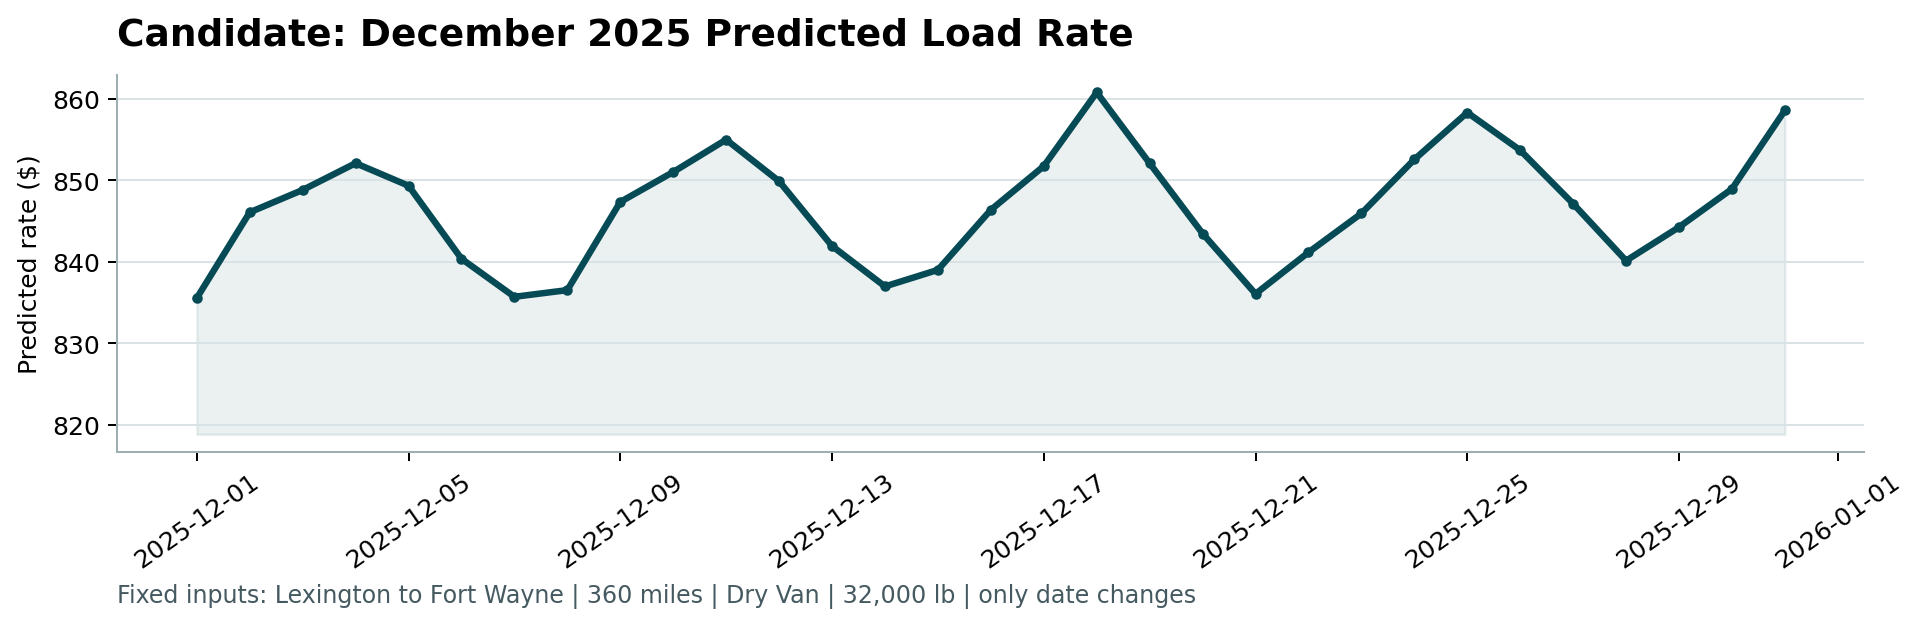

In [ ]:
import subprocess
import sys


def find_optional(*names):
    for n in names:
        if (DATA / n).exists():
            return DATA / n
    return None


OUT = DATA / 'outputs'
OUT.mkdir(exist_ok=True)

# 1) validation_predictions.csv — keeps the template's load_id order
template_path = find_optional('validation_predictions_template.csv', 'validation-predictions-template.csv')
pred_by_id = pd.Series(valid_pred, index=valid_c['load_id'].to_numpy())
if template_path is not None:
    sub = pd.read_csv(template_path)[['load_id']]
else:
    print('WARNING: template not found, using validation.csv order')
    sub = valid_c[['load_id']].copy()
sub['predicted_rate'] = sub['load_id'].map(pred_by_id).round(2)
assert len(sub) == 12_000 and sub['predicted_rate'].notna().all() and sub['load_id'].is_unique
sub.to_csv(OUT / 'validation_predictions.csv', index=False)

# 2) december_chart_inputs.csv — the original file, only predicted_rate filled
dec_raw = pd.read_csv(find_optional('december_chart_inputs.csv', 'december-chart-inputs.csv'))
assert (pd.to_datetime(dec_raw['date']).to_numpy() == dec_c['date'].to_numpy()).all()
dec_raw['predicted_rate'] = dec_pred.round(2)
dec_raw.to_csv(OUT / 'december_chart_inputs.csv', index=False)

# 3) Validate with score.py and draw the chart
score_path = find_optional('score.py') or Path('score.py')
r = subprocess.run([sys.executable, str(score_path),
                    '--predictions', str(OUT / 'validation_predictions.csv'),
                    '--december-predictions', str(OUT / 'december_chart_inputs.csv'),
                    '--output-dir', str(OUT / 'scorer_results')], capture_output=True, text=True)
print(r.stdout, r.stderr)

from IPython.display import Image
display(Image(str(OUT / 'scorer_results' / 'candidate_december.png'), width=900))

### 6.4 Improvement experiments
Each variant goes through the same protocol (3 time folds + cold start, clean labels):
- **B − dow:** day-of-week feature removed (importance ~0).
- **B + lane encoding:** 88% of validation rows are on known lanes → the lane's historical mean (training part only; out-of-fold for training rows; smoothed) is added as a feature. Unseen lanes get NaN; to teach the model that case, the value is deliberately hidden for 15% of training rows.
- **B per equipment:** Flatbed error is higher (2.9% vs Dry Van 1.7%) → a separate model per equipment.
- **B + C average:** (geometric) average of the two set-ups' predictions.

In [ ]:
# 6.4 Experiment harness: each variant is a (fit, predict) pair → same folds, same cleaning, same metrics
def run_variant(fit_fn, pred_fn):
    res = {}
    for start, tr_idx, te_idx in temporal_folds(train_c):
        trn = train_c.loc[tr_idx]
        trn = trn[~outlier_mask(trn)]
        tst = train_c.loc[te_idx]
        clean = (~outlier_mask(tst)).to_numpy()
        p = np.asarray(pred_fn(fit_fn(trn), tst), dtype=float)[clean]
        y = tst['posted_rate'].to_numpy()[clean]
        res[f'MAPE_{start[5:7]}'] = np.mean(np.abs(p - y) / y)
        if start == FOLDS[-1][0]:
            res['bias_F3'] = np.median(p / y - 1)
            eq = tst['equipment'].to_numpy()[clean]
            for e in ['Dry Van', 'Flatbed', 'Reefer']:
                m = eq == e
                res[f'F3_{e}'] = np.mean(np.abs(p[m] - y[m]) / y[m])
    res['MAPE_time_mean'] = np.mean([res['MAPE_05'], res['MAPE_07'], res['MAPE_09']])
    cold = evaluate_cold(train_c, lambda a, b: pred_fn(fit_fn(a), b))
    res['MAPE_cold'] = cold.loc[cold.view == 'clean', 'MAPE'].mean()
    return res


# --- Lane target encoding: training part only, out-of-fold for training rows ---
TE_M = 5            # smoothing toward the global mean for rarely seen lanes
TE_MASK = 0.15      # hide the lane value for 15% of training rows → the model also learns the new-lane (NaN) case


def lane_key(df):
    return (df['pickup'] + '→' + df['delivery']).reset_index(drop=True)


def lane_table(train, y):
    g = pd.DataFrame({'k': lane_key(train), 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
    return g, float(np.mean(y))


def te_from(table, keys):
    g, mu = table
    s, n = keys.map(g['sum']), keys.map(g['count'])
    return ((s + TE_M * mu) / (n + TE_M)).to_numpy()          # unseen lane → NaN


def oof_lane_te(train, y, k=5, seed=0):
    keys = lane_key(train)
    out_ = np.full(len(train), np.nan)
    fold = np.random.default_rng(seed).integers(0, k, len(train))
    for f in range(k):
        m = fold != f
        out_[~m] = te_from(lane_table(train.iloc[m], y[m]), keys[~m])
    out_[np.random.default_rng(seed + 1).random(len(train)) < TE_MASK] = np.nan
    return out_


# --- Parametric GBM-B: hyperparameters, dropped features, lane encoding ---
def fit_b(train, params=GBM_PARAMS, drop=(), lane_te=False):
    beta = trend_beta(train)
    t = ((train['date'] - T_START).dt.days / 30).to_numpy()
    y = log_rpm(train) - beta * t
    X = make_X(train, with_trend=False).drop(columns=list(drop))
    table = None
    if lane_te:
        X['lane_te'] = oof_lane_te(train, y)
        table = lane_table(train, y)
    model = lgb.LGBMRegressor(**params).fit(X, y)
    return {'model': model, 'beta': beta, 'drop': drop, 'table': table}


def pred_b(s, df):
    t = ((df['date'] - T_START).dt.days / 30).to_numpy()
    X = make_X(df, with_trend=False).drop(columns=list(s['drop']))
    if s['table'] is not None:
        X['lane_te'] = te_from(s['table'], lane_key(df))
    return df['distance'].to_numpy() * np.exp(s['model'].predict(X) + s['beta'] * t)


# --- One model per equipment ---
def fit_per_eq(train, **kw):
    return {e: fit_b(train[train['equipment'] == e], **kw) for e in train['equipment'].unique()}


def pred_per_eq(s, df):
    p = np.full(len(df), np.nan)
    eq = df['equipment'].to_numpy()
    for e, st in s.items():
        m = eq == e
        if m.any():
            p[m] = pred_b(st, df[m])
    return p


# --- GBM-B + GBM-C average (log scale) ---
def fit_ens(train):
    return {'b': fit_b(train), 'c': fit_gbm_twostage(train)}


def pred_ens(s, df):
    return np.sqrt(pred_b(s['b'], df) * predict_gbm_twostage(*s['c'], df))


VARIANTS = {
    'B (current)': (fit_b, pred_b),
    'B − dow': (lambda tr_: fit_b(tr_, drop=('dow',)), pred_b),
    'B + lane encoding': (lambda tr_: fit_b(tr_, lane_te=True), pred_b),
    'B per equipment': (fit_per_eq, pred_per_eq),
    'B + C average': (fit_ens, pred_ens),
}
exp_results = {}

In [ ]:
# Run the variants (takes a few minutes); results accumulate in exp_results
for name, (f, p) in VARIANTS.items():
    if name not in exp_results:
        exp_results[name] = run_variant(f, p)
cols = ['MAPE_time_mean', 'MAPE_05', 'MAPE_07', 'MAPE_09', 'MAPE_cold', 'bias_F3', 'F3_Dry Van', 'F3_Flatbed', 'F3_Reefer']
display(pd.DataFrame(exp_results).T[cols].round(4))

,MAPE_time_mean,MAPE_05,MAPE_07,MAPE_09,MAPE_cold,bias_F3,F3_Dry Van,F3_Flatbed,F3_Reefer
B (current),0.0284,0.0175,0.0473,0.0203,0.0212,-0.0141,0.0171,0.0286,0.0214
B − dow,0.0288,0.0180,0.0485,0.0200,0.0211,-0.0128,0.0168,0.0281,0.0212
B + lane encoding,0.0282,0.0175,0.0471,0.0202,0.0213,-0.0141,0.0171,0.0282,0.0212
B per equipment,0.0288,0.0180,0.0476,0.0207,0.0214,-0.0139,0.0172,0.0294,0.0220
B + C average,0.0281,0.0167,0.0473,0.0203,0.0211,-0.0139,0.0174,0.0278,0.0213


**Finding:** all five variants are within 0.05 points (time mean 2.81–2.88%, F3 2.00–2.07%, cold 2.11–2.14%) → differences are noise.
- **Lane encoding adds nothing:** a lane is a pair of pickup/delivery coordinates, which the GBM already learns. (Generalizing to new cities without city IDs costs nothing.)
- **Per-equipment models are worse:** each model sees fewer rows; equipment is already a feature in the single model.
- **B + C average** has the best time mean, but the gain is too small for the extra complexity.
- Removing **dow** changes nothing.

### 6.5 Optimistic lower bound (random split) and hyperparameter search

In [ ]:
# Equipment breakdown (right-hand columns of the previous table)
display(pd.DataFrame(exp_results).T[['F3_Dry Van', 'F3_Flatbed', 'F3_Reefer']].round(4))

# Optimistic lower bound (same-day loads can be in both training and test, so this is optimistic):
# how good can the model be without time extrapolation?
from sklearn.model_selection import KFold
full = train_c[~outlier_mask(train_c)].reset_index(drop=True)
ape = np.zeros(len(full))
for tr_i, te_i in KFold(5, shuffle=True, random_state=0).split(full):
    s = fit_b(full.iloc[tr_i])
    p = pred_b(s, full.iloc[te_i])
    ape[te_i] = np.abs(p - full['posted_rate'].to_numpy()[te_i]) / full['posted_rate'].to_numpy()[te_i]
print(f'Random 5-fold MAPE (no time extrapolation, lower-bound estimate): {ape.mean():.4f}')

,F3_Dry Van,F3_Flatbed,F3_Reefer
B (current),0.0171,0.0286,0.0214
B − dow,0.0168,0.0281,0.0212
B + lane encoding,0.0171,0.0282,0.0212
B per equipment,0.0172,0.0294,0.0220
B + C average,0.0174,0.0278,0.0213


Random 5-fold MAPE (no time extrapolation, lower-bound estimate): 0.0142


In [ ]:
# Small hyperparameter search (GBM-B); few, meaningful combinations to avoid overfitting the folds
GRID = {
    'current (63 leaves, 40 min, 800×0.03)': {},
    '31 leaves': dict(num_leaves=31),
    '127 leaves': dict(num_leaves=127),
    'min_child 100': dict(min_child_samples=100),
    'min_child 15': dict(min_child_samples=15),
    '1600×0.015 (slower learning)': dict(n_estimators=1600, learning_rate=0.015),
}
hp_results = {}
for name, over in GRID.items():
    params = {**GBM_PARAMS, **over}
    hp_results[name] = run_variant(lambda tr_, p=params: fit_b(tr_, params=p), pred_b)
display(pd.DataFrame(hp_results).T[['MAPE_time_mean', 'MAPE_05', 'MAPE_07', 'MAPE_09', 'MAPE_cold', 'bias_F3']].round(4))

,MAPE_time_mean,MAPE_05,MAPE_07,MAPE_09,MAPE_cold,bias_F3
"current (63 leaves, 40 min, 800×0.03)",0.0284,0.0175,0.0473,0.0203,0.0212,-0.0141
31 leaves,0.0284,0.0176,0.0470,0.0205,0.0212,-0.0141
127 leaves,0.0284,0.0176,0.0475,0.0202,0.0213,-0.0139
min_child 100,0.0285,0.0176,0.0474,0.0204,0.0212,-0.0142
min_child 15,0.0284,0.0175,0.0474,0.0203,0.0212,-0.0140
1600×0.015 (slower learning),0.0284,0.0175,0.0474,0.0203,0.0213,-0.0141


### 6.6 Does `quote_signal` carry information inside the GBM?
The EDA only used simple tests (naive MAPE, within-band correlation). Since validation.csv contains this column, the claim is tested directly: the same model with `quote_signal` added as a feature.

In [ ]:
# Does quote_signal carry information inside the GBM? (direct test of the claim)
train_c['quote_signal'] = tr['quote_signal']
make_X_orig = make_X
make_X = lambda df, with_trend=True: make_X_orig(df, with_trend).assign(quote_signal=df['quote_signal'])
try:
    res_qs = run_variant(fit_b, pred_b)
finally:
    make_X = make_X_orig
    train_c = train_c.drop(columns='quote_signal')
display(pd.DataFrame({'B (current)': exp_results['B (current)'], 'B + quote_signal': res_qs}).T[
    ['MAPE_time_mean', 'MAPE_05', 'MAPE_07', 'MAPE_09', 'MAPE_cold', 'bias_F3']].round(4))

,MAPE_time_mean,MAPE_05,MAPE_07,MAPE_09,MAPE_cold,bias_F3
B (current),0.0284,0.0175,0.0473,0.0203,0.0212,-0.0141
B + quote_signal,0.0289,0.0186,0.0524,0.0157,0.0168,-0.0055


**Finding (6.6) — correcting the EDA claim:** with `quote_signal` in the GBM, F3 MAPE drops 2.03% → **1.57%**, cold start 2.12% → **1.68%**, F3 bias −1.41% → −0.55%. So `quote_signal` **does carry information**: the EDA compared it with raw price, but the signal sits in the small residual left after location/distance/market. However F1 (1.75% → 1.86%) and F2 (4.73% → 5.24%) get **worse**; the time mean goes 2.84% → 2.89%. The diagnosis below explains why.

In [ ]:
# 6.6b Does quote_signal carry information, and is that information stable over time?
# (1) Per load or a market quote? Does qs differ within the same day + lane + equipment?
g = tr.groupby(['date', 'pickup', 'delivery', 'equipment']).quote_signal
multi = g.size() > 1
print(f'Share of {int(multi.sum())} multi-row groups where qs differs: {float((g.nunique()[multi] > 1).mean()):.3f}')

# (2) Relationship with what the model cannot explain (F3 residual), by distance band
e2 = err.assign(qs=tr.loc[err.index, 'quote_signal'], resid=np.log(err['posted_rate'] / err['pred']))
display(e2.groupby('dist_band', observed=True)[['resid', 'qs']]
          .apply(lambda d: np.corrcoef(d.resid, np.log(d.qs))[0, 1]).round(3).to_frame('corr(residual, log qs)').T)

# (3) Random split (no time effect): does qs lower the error?
full_q = full.assign(quote_signal=tr.loc[train_c[~outlier_mask(train_c)].index, 'quote_signal'].to_numpy())
mx = make_X
make_X = lambda df, with_trend=True: mx(df, with_trend).assign(quote_signal=df['quote_signal'])
try:
    ape_q = np.zeros(len(full_q))
    for tr_i, te_i in KFold(5, shuffle=True, random_state=0).split(full_q):
        p = pred_b(fit_b(full_q.iloc[tr_i]), full_q.iloc[te_i])
        y = full_q['posted_rate'].to_numpy()[te_i]
        ape_q[te_i] = np.abs(p - y) / y
finally:
    make_X = mx
print(f'Random 5-fold MAPE: without qs {ape.mean():.4f} | with qs {ape_q.mean():.4f}')

# (4) Does qs follow the corrupted (outlier) prices?
o = outlier_mask(train_c)
ratio_q = tr['posted_rate'] / (tr['distance'] * tr['quote_signal'])
print(f'median price/(distance×qs): clean {ratio_q[~o].median():.3f} | outlier-up {ratio_q[o & (tr.rz > 0)].median():.3f} | outlier-down {ratio_q[o & (tr.rz < 0)].median():.3f}')

# (5) Is the qs–price relationship stable across months? (clean rows)
cm = tr.loc[(~o)[~o].index]
display(pd.DataFrame({'price/(distance×qs) median': ratio_q.loc[cm.index].groupby(cm.date.dt.month).median(),
                      'qs mean': cm.quote_signal.groupby(cm.date.dt.month).mean()}).round(3).T)
print('Validation qs mean (Nov, Dec):', va.quote_signal.groupby(va.date.dt.month).mean().round(3).tolist())

Share of 488 multi-row groups where qs differs: 1.000


dist_band,"(0, 250]","(250, 500]","(500, 1000]","(1000, 2000]","(2000, 4000]"
"corr(residual, log qs)",0.248,0.241,0.266,0.176,-0.004


Random 5-fold MAPE: without qs 0.0142 | with qs 0.0123
median price/(distance×qs): clean 1.004 | outlier-up 3.615 | outlier-down 0.300


date,1,2,3,4,5,6,7,8,9,10
price/(distance×qs) median,1.000,1.000,1.000,1.072,1.118,1.000,1.114,1.040,1.0,1.092
qs mean,2.068,2.096,2.179,1.965,1.913,2.297,1.923,2.053,2.2,1.943


Validation qs mean (Nov, Dec): [2.055, 2.048]


In [ ]:
# (6) Monthly regime: is qs an exact copy of the target in some months? Which regime is validation in?
exact = (ratio_q.loc[cm.index] - 1).abs() < 0.002          # price = distance × qs (±0.2%)
t_ratio = predict_gbm_detrend(final_model, final_beta, train_c.loc[cm.index]) / (cm['distance'] * cm['quote_signal'])
mon = cm.date.dt.month
reg = pd.DataFrame({'exact copy of target (%)': exact.groupby(mon).mean() * 100,
                    'model/(distance×qs) median': t_ratio.groupby(mon).median(),
                    'model/(distance×qs) within ±2% (%)': (np.abs(t_ratio - 1) < 0.02).groupby(mon).mean() * 100})
# Validation has no labels: the same measure uses the final model's prediction (which does not use qs)
v_ratio = pd.Series(valid_pred / (valid_c['distance'].to_numpy() * va['quote_signal'].to_numpy()), index=va.index)
vm = va['date'].dt.month
for mo in [11, 12]:
    s = v_ratio[vm == mo]
    reg.loc[mo] = [np.nan, s.median(), (np.abs(s - 1) < 0.02).mean() * 100]
display(reg.round(3).T)

date,1,2,3,4,5,6,7,8,9,10,11,12
exact copy of target (%),15.030,15.187,15.871,0.652,0.804,15.975,0.660,1.109,15.502,0.545,NaN,NaN
model/(distance×qs) median,1.000,0.999,0.998,1.072,1.122,0.997,1.117,1.044,0.999,1.089,1.068,1.073
model/(distance×qs) within ±2% (%),72.173,72.150,73.192,7.490,7.401,72.394,6.602,10.531,72.818,7.102,8.705,9.831


**Finding (6.6b) — `quote_signal` contains a month-dependent target leak:**

| Months | Exact copy of the target | model/(distance×qs) within ±2% | Median ratio |
|---|---|---|---|
| Jan, Feb, Mar, Jun, Sep | **~15–16%** | ~72–73% | ~1.00 |
| Apr, May, Jul, Aug, Oct | ~0.5–1% | ~7–10% | 1.04–1.12 |
| **Nov, Dec (validation)** | (no labels) | **8.7% / 9.8%** | **1.07** |

- `quote_signal` differs between loads on the same day + lane + equipment → a load-level value, not a market quote. It does not follow the corrupted prices → it seems derived from the price before corruption.
- In the "copy months" `quote_signal` is the price itself (~15% of rows match within ±0.2%); in the other months it is 4–12% below the price and noisy.
- This explains the fold results: the F3 gain (2.03% → 1.57%) comes from September being a copy month; the F2 loss (4.73% → 5.24%) from July–August being non-copy months. The model learns "qs ≈ price" from the copy months and misapplies it in the others.
- **The validation months look like the non-copy regime** (ratio 1.07, only ~9% within ±2%) → adding `quote_signal` would hurt there, as it did on F2.

**Decision:** `quote_signal` is not used. The reason is not the EDA's "carries no information" but: **(1) a month-dependent target leak, (2) validation sits in the non-leaking regime, (3) the December file lacks it.** The first EDA test (correlation with raw price) could not reveal this structure; it had to be tested directly inside the model.

### 6.7 Why is Flatbed error higher?
On F3, Flatbed MAPE (2.86%) is noticeably higher than Dry Van (1.71%) and Reefer (2.14%). Below we test whether this is static load-level noise or a time-related level shift.

In [ ]:
# Is Flatbed's higher error the model or the data? If it is also high on random splits → the data's own noise
display(pd.Series(ape).groupby(full['equipment'].to_numpy()).mean().round(4).to_frame('random_5fold_MAPE').T)

,Dry Van,Flatbed,Reefer
random_5fold_MAPE,0.0137,0.0156,0.0143


In [ ]:
# Does Flatbed behave differently over time? Elasticity and trend per equipment (all training) + F3 bias by equipment × month
rows = []
for e in ['Dry Van', 'Flatbed', 'Reefer']:
    d = full[full['equipment'] == e]
    b, *_ = np.linalg.lstsq(lin_design(d), log_rpm(d), rcond=None)
    rows.append({'equipment': e, 'n': len(d), 'log(mi) elasticity': b[2], 'trend_per_month': b[3]})
display(pd.DataFrame(rows).set_index('equipment').round(4))
display(err.groupby(['equipment', 'month']).bias.median().unstack().round(4))

# Monthly level: rpm_rel median by equipment
display(tr.groupby([tr['equipment'], tr['date'].dt.month]).rpm_rel.median().unstack().round(3))

,n,log(mi) elasticity,trend_per_month
equipment,,,
Dry Van,26834,0.1556,0.0063
Flatbed,8626,0.1505,0.0069
Reefer,11863,0.1519,0.0065


month,9,10
equipment,,
Dry Van,-0.0118,-0.0117
Flatbed,-0.0390,-0.0104
Reefer,-0.0238,-0.0106


date,1,2,3,4,5,6,7,8,9,10
equipment,,,,,,,,,,
Dry Van,0.948,0.964,0.989,1.003,1.026,1.043,1.021,0.990,0.998,1.010
Flatbed,0.941,0.956,1.012,0.997,1.019,1.064,1.017,0.987,1.021,1.001
Reefer,0.946,0.960,0.996,1.001,1.023,1.052,1.019,0.986,1.006,1.004


**Conclusion (6.4–6.7):**
- **Hyperparameters:** all six settings give 2.84–2.85% (cold 2.12–2.13%) → the model is insensitive to them; current settings are kept.
- **Optimistic lower bound:** without time extrapolation (random folds) MAPE is **1.42%**; on time-based F3 it is 2.03%. Most of the remaining error is the data's own noise; ~0.6 points come from monthly level moves that `mi` + trend do not explain (see 6.1c–d). Neither can be closed with the available features.
- **Flatbed:** on random folds its error is close to the others (1.56% vs Dry Van 1.37%), but on time-based F3 it is clearly higher (2.86% vs 1.71%) → the issue is **time-related**, not noise. Elasticity and trend are the same across equipment (0.151–0.156; 0.63–0.69%/month), but Flatbed's monthly level is more volatile (e.g. March 1.012 vs Dry Van 0.989, June 1.064 vs 1.043, September 1.021 vs 0.998). F3 bias in September: Flatbed −3.9%, Dry Van −1.2%. This is equipment-specific monthly movement that `mi` does not capture; ten months of data cannot learn it for November–December (it may be consistent with construction-season demand for flatbeds — an untested hypothesis). Per-equipment models did not fix it.
- **`quote_signal`:** a month-dependent target leak; not used (6.6).

**Decision:** final model **GBM-B with the current hyperparameters** — no change improved results beyond noise, so the simplest version is kept. The deliverables (6.3) were produced with this model. Flatbed's monthly volatility is reported as a known limitation.

## 7. Reproduction
The production code in this repository reproduces this notebook's predictions exactly (maximum difference $0.00):

```bash
python run_pipeline.py      # deliverables + score.py chart
python run_validation.py    # baseline vs final model comparison (Table 3 of the report)
pytest -q                   # leakage rules and output formats on synthetic data
```